# GNN ablation study — environment × phylogeny

This notebook analyzes `results_all.parquet`, produced by the **newzeland-plants** benchmark.

Objectives:

- verify that the design is complete and balanced across the four configurations;
- reconstruct **per-seed** metrics while preserving pairing across configurations;
- quantify the marginal effects of environment and phylogeny;
- distinguish between *absence of evidence of a difference* and *practical equivalence*;
- identify traits/variables and seeds for which the different inputs help or hurt;
- visualize potential environment × phylogeny interactions.

The convention used for contrasts is **positive benefit = better treatment**. For error metrics, the benefit is therefore `reference - treatment`; for metrics where higher values are better, it is `treatment - reference`.

> The notebook does not assume that every seed is present. Each paired comparison automatically uses only the seeds available in both configurations. After regenerating a missing seed, simply rerun all cells.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_SEED = 20261001
rng = np.random.default_rng(RANDOM_SEED)

# Primary metric. The notebook automatically selects a fallback if it is unavailable.
PREFERRED_METRIC = "NRMSE_IQR"

# Set to a scientifically justified value (e.g. 0.02) to run the TOST.
# None = no equivalence conclusion.
EQUIVALENCE_MARGIN = 0.02

import sys
sys.path.insert(0, str(next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analysis_utils.py").is_file())))
from analysis_utils import CONFIGURATION_ORDER, CONFIGURATION_LABELS, TRAIT_ORDER, TRAIT_LABELS, BOUND_ORDER

# Canonical names and orderings shared by all notebooks (analysis_utils.py).
CONFIG_ORDER = list(CONFIGURATION_ORDER)
CONFIG_LABELS = CONFIGURATION_LABELS

ROOT = Path.cwd().parent.resolve()
DEFAULT_RESULTS_PATH = ROOT / "benchmark_results/results_ablation.parquet"

CONTRASTS = [
    ("Environment without phylogeny", "baseline", "environment"),
    ("Environment with phylogeny", "phylogeny", "full"),
    ("Phylogeny without environment", "baseline", "phylogeny"),
    ("Phylogeny with environment", "environment", "full"),
    ("Phylogeny and environment vs. baseline", "baseline", "full")
]

## 1. Loading and schema normalization

In [2]:
gnn = pd.read_parquet(DEFAULT_RESULTS_PATH)

## 3. Fold → seed × trait × variable aggregation

The repository dashboard aggregates RMSE across folds as the square root of the weighted mean of squared RMSE values, MAE as a weighted mean, and correlations using Fisher's transformation. The same logic is applied here.

In [3]:
def weighted_fisher_mean(values: pd.Series, weights: pd.Series) -> float:
    valid = values.notna() & weights.notna() & (weights > 0)
    if not valid.any():
        return np.nan
    v = values.loc[valid].clip(-0.999999, 0.999999).to_numpy(float)
    w = np.maximum(weights.loc[valid].to_numpy(float) - 3.0, 1.0)
    return float(np.tanh(np.average(np.arctanh(v), weights=w)))


def aggregate_metric_group(group: pd.DataFrame) -> dict:
    weights = group["n"].fillna(1).clip(lower=0) if "n" in group else pd.Series(1.0, index=group.index)
    out = {"n": float(weights.sum())}

    for col in ["RMSE", "NRMSE_IQR", "NRMSE_range"]:
        if col in group:
            valid = group[col].notna() & (weights > 0)
            out[col] = (
                float(np.sqrt(np.average(np.square(group.loc[valid, col]), weights=weights.loc[valid])))
                if valid.any() else np.nan
            )

    for col in ["MAE", "NMAE_IQR"]:
        if col in group:
            valid = group[col].notna() & (weights > 0)
            out[col] = (
                float(np.average(group.loc[valid, col], weights=weights.loc[valid]))
                if valid.any() else np.nan
            )

    for col in ["Pearson_r", "Spearman_rho"]:
        if col in group:
            out[col] = weighted_fisher_mean(group[col], weights)

    return out


group_cols = ["configuration_id", "configuration", "seed", "trait", "variable"]
records = []
for key, group in gnn.groupby(group_cols, dropna=False, sort=False):
    rec = dict(zip(group_cols, key))
    rec.update(aggregate_metric_group(group))
    rec["folds"] = group["fold"].nunique() if "fold" in group.columns else len(group)
    records.append(rec)

seed_slice = pd.DataFrame(records)

candidate_metrics = [
    PREFERRED_METRIC, "NRMSE_range", "RMSE", "MAE", "Pearson_r", "Spearman_rho"
]
METRIC = next((m for m in candidate_metrics if m in seed_slice.columns and seed_slice[m].notna().any()), "")
if METRIC is None:
    raise ValueError("No supported metric found in the parquet file.")

LOWER_IS_BETTER = METRIC not in {"Pearson_r", "Spearman_rho"}
print(f"Selected primary metric: {METRIC} | lower_is_better={LOWER_IS_BETTER}")
print(f"Seed × slice rows: {len(seed_slice):,}")
display(seed_slice.head())

Selected primary metric: NRMSE_IQR | lower_is_better=True
Seed × slice rows: 2,880


,configuration_id,configuration,seed,trait,variable,n,RMSE,NRMSE_IQR,NRMSE_range,MAE,NMAE_IQR,Pearson_r,Spearman_rho,folds
0,baseline,Nessun input accessorio,111.0000,FertileFrond,min,170.0000,350.6431,2.0872,0.1169,116.9524,0.6961,0.7097,0.8926,5
1,baseline,Nessun input accessorio,111.0000,Ferstipe,max,165.0000,195.4318,0.4158,0.1184,124.7551,0.2654,0.8680,0.9142,5
2,baseline,Nessun input accessorio,111.0000,SterileStipe,min,165.0000,74.0868,1.4817,0.0741,23.1947,0.4639,0.7713,0.9150,5
3,baseline,Nessun input accessorio,111.0000,SterileStipe,max,165.0000,215.4667,0.4584,0.1306,134.4991,0.2862,0.8489,0.9072,5
4,baseline,Nessun input accessorio,111.0000,FertileFrond,max,170.0000,557.6749,0.6103,0.1116,297.7872,0.3259,0.8259,0.8935,5


## 4. Common seeds and overall summary by configuration

,configuration_id,configuration,n_seeds,mean,sd,median,q25,q75
0,baseline,Nessun input accessorio,60,4.5984,0.0429,4.5910,4.5797,4.6023
1,environment,Solo ambiente,60,4.5977,0.0229,4.5953,4.5817,4.6125
3,phylogeny,Solo filogenesi,60,4.5322,0.0929,4.5122,4.4857,4.5440
2,full,Ambiente + filogenesi,60,4.5250,0.0806,4.5106,4.4855,4.5403


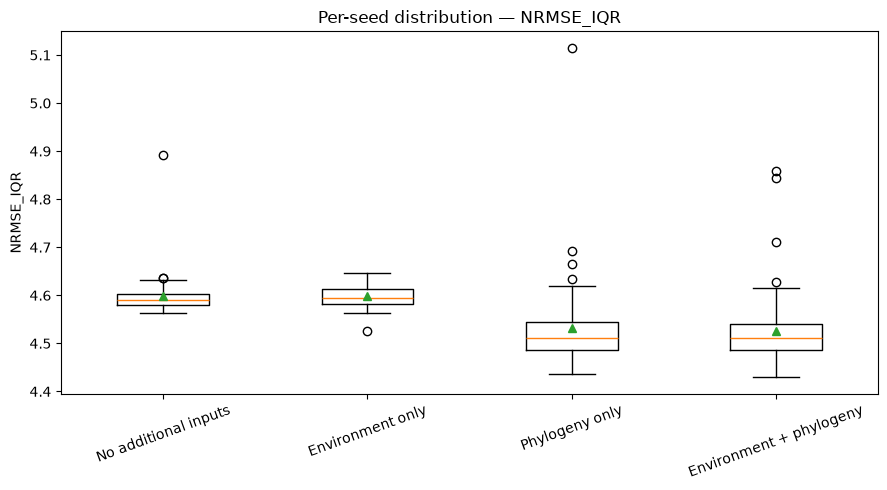

In [4]:
seed_sets = {
    cfg: set(seed_slice.loc[seed_slice["configuration_id"].eq(cfg), "seed"].dropna().unique())
    for cfg in CONFIG_ORDER
}
common_seeds = sorted(set.intersection(*(seed_sets[cfg] for cfg in CONFIG_ORDER)))
# print(f"Seeds present in all configurations: {len(common_seeds)}")
# print(common_seeds)

common = seed_slice.loc[seed_slice["seed"].isin(common_seeds)].copy()
seed_overall = (
    common.groupby(["seed", "configuration_id", "configuration"], as_index=False)[METRIC]
          .mean()
)

summary_cfg = (
    seed_overall.groupby(["configuration_id", "configuration"], as_index=False)
                .agg(
                    n_seeds=("seed", "nunique"),
                    mean=(METRIC, "mean"),
                    sd=(METRIC, "std"),
                    median=(METRIC, "median"),
                    q25=(METRIC, lambda x: x.quantile(.25)),
                    q75=(METRIC, lambda x: x.quantile(.75)),
                )
)
summary_cfg["configuration_id"] = pd.Categorical(summary_cfg["configuration_id"], CONFIG_ORDER, ordered=True)
summary_cfg = summary_cfg.sort_values("configuration_id")
display(summary_cfg)

fig, ax = plt.subplots(figsize=(9, 5))
data = [seed_overall.loc[seed_overall.configuration_id.eq(cfg), METRIC].dropna().values for cfg in CONFIG_ORDER]
ax.boxplot(data, showmeans=True)
ax.set_ylabel(METRIC)
ax.set_xticklabels([CONFIG_LABELS[c] for c in CONFIG_ORDER])
ax.set_title(f"Per-seed distribution — {METRIC}")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [5]:
print(summary_cfg.set_index("configuration_id")[["median"]].to_markdown())

| configuration_id   |   median |
|:-------------------|---------:|
| baseline           |  4.59101 |
| environment        |  4.59526 |
| phylogeny          |  4.51222 |
| full               |  4.51056 |


## 5. Paired factorial contrasts — main table

Each contrast starts from a per-seed value obtained by averaging the trait/variable slices. For each contrast, the table reports:

- mean and median benefit;
- standard deviation and 95% CI of the mean;
- share of improved seeds;
- paired t-test;
- Wilcoxon signed-rank test;
- paired sign-flip permutation test;
- Cohen's *d<sub>z</sub>*;
- Holm correction of the four permutation-test p-values.

In [6]:
def paired_benefit_table(per_seed: pd.DataFrame, metric: str, lower_is_better: bool, n_perm: int = 20000):
    wide = per_seed.pivot(index="seed", columns="configuration_id", values=metric)
    results = []
    deltas = {}

    for label, reference, treatment in CONTRASTS:
        pair = wide[[reference, treatment]].dropna()
        if lower_is_better:
            d = pair[reference] - pair[treatment]
        else:
            d = pair[treatment] - pair[reference]
        d = d.astype(float)
        deltas[label] = d

        n = len(d)
        mean = d.mean() if n else np.nan
        median = d.median() if n else np.nan
        sd = d.std(ddof=1) if n > 1 else np.nan
        sem = sd / np.sqrt(n) if n > 1 else np.nan
        tcrit = stats.t.ppf(0.975, df=n - 1) if n > 1 else np.nan
        ci_low = mean - tcrit * sem if n > 1 else np.nan
        ci_high = mean + tcrit * sem if n > 1 else np.nan
        improved_share = float((d > 0).mean()) if n else np.nan

        t_p = stats.ttest_1samp(d, 0.0, nan_policy="omit").pvalue if n > 1 else np.nan
        try:
            w_p = stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided").pvalue if n > 0 else np.nan
        except ValueError:
            w_p = 1.0

        if n > 0:
            signs = rng.choice([-1.0, 1.0], size=(n_perm, n))
            perm_means = (signs * d.to_numpy()).mean(axis=1)
            perm_p = (np.sum(np.abs(perm_means) >= abs(mean)) + 1) / (n_perm + 1)
        else:
            perm_p = np.nan

        dz = mean / sd if n > 1 and sd > 0 else np.nan

        results.append({
            "comparison": label,
            "reference": CONFIG_LABELS[reference],
            "treatment": CONFIG_LABELS[treatment],
            "n_seeds": n,
            "mean_benefit": mean,
            "median_benefit": median,
            "sd_benefit": sd,
            "ci95_low": ci_low,
            "ci95_high": ci_high,
            "improved_share": improved_share,
            "paired_t_p": t_p,
            "wilcoxon_p": w_p,
            "permutation_p": perm_p,
            "cohen_dz": dz,
        })

    out = pd.DataFrame(results)
    valid = out["permutation_p"].notna()
    out["permutation_p_holm"] = np.nan
    if valid.any():
        out.loc[valid, "permutation_p_holm"] = multipletests(
            out.loc[valid, "permutation_p"], method="holm"
        )[1]
    return out, deltas


contrast_table, contrast_deltas = paired_benefit_table(seed_overall, METRIC, LOWER_IS_BETTER)
formatted = contrast_table.copy()
formatted["improved_share"] *= 100
formatted = formatted.drop(columns=["n_seeds", "mean_benefit"])

In [7]:

display(
    formatted.style.format({
        "mean_benefit": "{:.4f}", "median_benefit": "{:.4f}", "sd_benefit": "{:.4f}",
        "ci95_low": "{:.4f}", "ci95_high": "{:.4f}", "improved_share": "{:.1f}%",
        "paired_t_p": "{:.3g}", "wilcoxon_p": "{:.3g}", "permutation_p": "{:.3g}",
        "permutation_p_holm": "{:.3g}", "cohen_dz": "{:.3f}",
    })
)

,comparison,reference,treatment,median_benefit,sd_benefit,ci95_low,ci95_high,improved_share,paired_t_p,wilcoxon_p,permutation_p,cohen_dz,permutation_p_holm
0,Environment without phylogeny,No additional inputs,Environment only,-0.0049,0.0408,-0.0098,0.0113,46.7%,0.888,0.373,0.919,0.018,1
1,Environment with phylogeny,Phylogeny only,Environment + phylogeny,0.0077,0.1022,-0.0193,0.0335,60.0%,0.59,0.453,0.626,0.070,1
2,Phylogeny without environment,No additional inputs,Phylogeny only,0.0752,0.1047,0.0392,0.0933,86.7%,7.89e-06,1.71e-08,5e-05,0.632,0.00025
3,Phylogeny with environment,Environment only,Environment + phylogeny,0.0813,0.0837,0.0510,0.0942,90.0%,7.97e-09,2.4e-08,5e-05,0.868,0.00025
4,Phylogeny and environment vs. baseline,No additional inputs,Environment + phylogeny,0.0801,0.0905,0.0500,0.0968,88.3%,4.44e-08,8.02e-08,5e-05,0.811,0.00025


### Boxplot of marginal effects

In [8]:
def mathtext_spaces(s):
    return str(s).replace(" ", r"\ ")

yticks = []

for label, reference, treatment in CONTRASTS:
    # label_fmt = mathtext_spaces(label)
    label_fmt = mathtext_spaces(CONFIG_LABELS[treatment])

    tick = (
        rf"$\mathbf{{{label_fmt}}}$"
        "\n"
        # f"{CONFIG_LABELS[treatment]}"
        r"$\mathit{w.r.t.}$"
        f"{CONFIG_LABELS[reference]} "
    )

    yticks.append(tick)


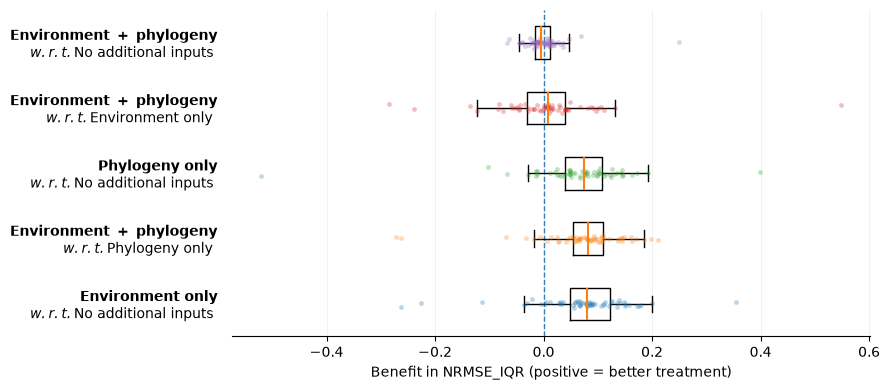

In [9]:
contrast_meta = pd.DataFrame(
    [
        {
            "comparison": label,
            "reference": CONFIG_LABELS[reference],
            "treatment": CONFIG_LABELS[treatment],
        }
        for label, reference, treatment in CONTRASTS
    ]
)

plot_df = (
    pd.concat(
        {
            label: d.reset_index(drop=True)
            for label, d in contrast_deltas.items()
        },
        names=["comparison", "obs"]
    )
    .rename("benefit")
    .reset_index()
    .drop(columns="obs")
    .merge(contrast_meta, on="comparison", how="left")
)

data = [
    contrast_deltas[label].to_numpy()
    for label, _, _ in CONTRASTS[::-1]
]

fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(len(data))
bp = ax.boxplot(
    data,
    positions=positions,
    orientation="horizontal",
    widths=0.5,
    patch_artist=False,
    showfliers=False,
    showmeans=False,
    medianprops={
        "linewidth": 1.5,
    },
    boxprops={
        "linewidth": 1.0,
    },
    whiskerprops={
        "linewidth": 1.0,
    },
    capprops={
        "linewidth": 1.0,
    },
)


# Overlay individual observations with slight vertical jitter
rng = np.random.default_rng(42)

for i, values in enumerate(data):
    jitter = rng.normal(0, 0.035, size=len(values))

    ax.scatter(
        values,
        np.full(len(values), positions[i]) + jitter,
        s=12,
        alpha=0.30,
        linewidths=0,
        zorder=2,
    )

# Reference line: no treatment benefit
ax.axvline(0,linewidth=1,linestyle="--",zorder=0)

# Axes
ax.set_yticks(positions)
ax.set_yticklabels(yticks)

ax.set_xlabel(f"Benefit in {METRIC} (positive = better treatment)")

# ax.set_title("Paired marginal effects",loc="left",fontweight="bold")

# Paper-style cleanup
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y",length=0,pad=10)

ax.grid(axis="x",linewidth=0.5,alpha=0.25)
ax.set_axisbelow(True)

# fig.savefig(ROOT / "figures/ablation_marginal_effects.pdf", bbox_inches="tight", dpi=300)
plt.tight_layout()
plt.show()


## 6. Effects by trait × variable

This table prevents an effect concentrated in a few slices from being hidden by the overall mean. Tests are paired across seeds, and p-values are adjusted with Benjamini–Hochberg across the set of analyzed slices.

In [10]:
def slice_contrasts(seed_slice: pd.DataFrame, metric: str, lower_is_better: bool) -> pd.DataFrame:
    records = []
    for (trait, variable), block in seed_slice.groupby(["trait", "variable"], sort=False):
        wide = block.pivot_table(index="seed", columns="configuration_id", values=metric, aggfunc="mean")
        for label, reference, treatment in CONTRASTS:
            if reference not in wide or treatment not in wide:
                continue
            pair = wide[[reference, treatment]].dropna()
            d = (pair[reference] - pair[treatment]) if lower_is_better else (pair[treatment] - pair[reference])
            if len(d) == 0:
                continue
            try:
                p = stats.wilcoxon(d, zero_method="wilcox").pvalue
            except ValueError:
                p = 1.0
            records.append({
                "trait": trait,
                "variable": variable,
                "comparison": label,
                "treatment": CONFIG_LABELS[treatment],
                "reference": CONFIG_LABELS[reference],
                "n_seeds": len(d),
                "mean_benefit": d.mean(),
                "median_benefit": d.median(),
                "improved_share": (d > 0).mean(),
                "wilcoxon_p": p,
            })
    out = pd.DataFrame(records)
    if not out.empty:
        out["wilcoxon_q_bh"] = multipletests(out["wilcoxon_p"], method="fdr_bh")[1]
    return out


slice_stats = slice_contrasts(common, METRIC, LOWER_IS_BETTER)

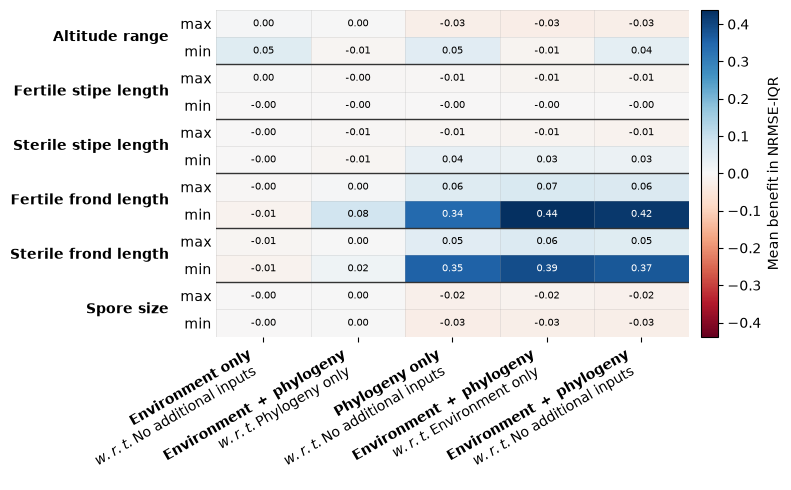

In [ ]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.transforms import ScaledTranslation

pretty_trait_map = TRAIT_LABELS
target_order = list(TRAIT_ORDER)

heat = slice_stats.pivot_table(
    index=["trait", "variable"],
    columns="comparison",
    values="mean_benefit",
    aggfunc="first",
)


ordered_index = pd.MultiIndex.from_tuples(
    [(t, v) for t in target_order for v in BOUND_ORDER if (t, v) in heat.index],
    names=["trait", "variable"]
)

heat = heat.reindex(
    index=ordered_index,
    columns=[c[0] for c in CONTRASTS]
    )

values = heat.to_numpy(dtype=float)

# Symmetric scale around zero for direct visual comparison
vmax = np.nanmax(np.abs(values))
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

fig, ax = plt.subplots(
    figsize=(9.5, 6.5)
)

im = ax.imshow(
    values,
    aspect="auto",
    interpolation="nearest",
    norm=norm,
    cmap="RdBu",
)

# Axis labels
ax.set_xticks(np.arange(len(heat.columns)))
ax.set_xticklabels(["Env vs Base", "Phylo + Env vs Phylo", "Phylo vs Base", "Phylo + Env vs Env", "Phylo + Env vs Base"], rotation=25, ha="right", fontsize=11)

# Two-level y axis taken directly from the pivot's MultiIndex:
#   inner level (variable) -> regular tick labels
#   outer level (trait)    -> bold group labels + separators
traits = heat.index.get_level_values("trait")
variables = heat.index.get_level_values("variable")

ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(variables, fontsize=11)

def pretty_trait(t):
    pretty = pretty_trait_map.get(t)
    if not pretty:
        raise ValueError(f"Unknown trait: {t}")
    return pretty

label_trans = ax.get_yaxis_transform() + ScaledTranslation(
    -34 / 72, 0, fig.dpi_scale_trans
)
start = 0
for i in range(1, len(traits) + 1):
    if i == len(traits) or traits[i] != traits[start]:
        ax.text(
            0, (start + i - 1) / 2, pretty_trait(traits[start]),
            transform=label_trans, ha="right", va="center",
            fontweight="bold", fontsize=11,
        )
        if i < len(traits):
            ax.axhline(i - 0.5, color="0.2", linewidth=1.0)
        start = i

# Fine grid between cells
ax.set_xticks(
    np.arange(-0.5, len(heat.columns), 1),minor=True,
)
ax.set_yticks(np.arange(-0.5, len(heat.index), 1),
    minor=True,)

ax.grid( which="minor", linewidth=0.5, alpha=0.35,)
ax.tick_params( which="minor", bottom=False, left=False,)
ax.tick_params(axis="y", which="major", length=0)

# Zero-centered visual meaning
cbar = fig.colorbar( im, ax=ax, fraction=0.035, pad=0.025,
)

cbar.set_label(
    f"Mean benefit in {METRIC.replace('_', '-')}"
)

for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        value = values[i, j]

        if np.isfinite(value):
            rgba = im.cmap(im.norm(value))
            r, g, b = rgba[:3]

            # Perceived luminance
            luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
            text_color = "white" if luminance < 0.45 else "black"
            ax.text(j,i,f"{value:.2f}",ha="center",va="center",fontsize=10,color=text_color,
            )
            
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
fig.savefig(ROOT / "figures/ablation_marginal_effects_slices.pdf", bbox_inches="tight", dpi=300)
fig.savefig(ROOT / "Paper/ablation_marginal_effects_slices.pdf", bbox_inches="tight", dpi=300)
plt.tight_layout()
plt.show()

## Ordered-bound check by species and trait
Compares saved original-scale minimum and maximum predictions for each seed and test fold. Change the model and configuration at the top of the next cell.


In [ ]:
# Change these inputs to inspect another model or GNN configuration.
MODEL_NAME = "gnn"
CONFIGURATION_ID = "env_phylo"  # env_phylo (phylo + env), phylo_only, env_only, no_env_no_phylo
RESULTS_ROOT = ROOT / "benchmark_results" / "runs"

import re
import seaborn as sns
from matplotlib.colors import ListedColormap

valid_configs = {"env_phylo", "phylo_only", "env_only", "no_env_no_phylo"}
if CONFIGURATION_ID not in valid_configs:
    raise ValueError(f"Unknown configuration: {CONFIGURATION_ID}; choose one of {sorted(valid_configs)}")

records = []
seen = set()
for seed_dir in sorted(RESULTS_ROOT.glob("seed_*")):
    match = re.fullmatch(r"seed_(\d+)", seed_dir.name)
    if not match:
        continue
    seed = int(match.group(1))
    if MODEL_NAME.lower() == "gnn":
        model_dirs = [d for d in (seed_dir / "gnn" / CONFIGURATION_ID).glob("*") if d.is_dir()]
    else:
        # Baselines are shared across graph configurations; MODEL_NAME is the exact saved directory name.
        model_dirs = [d for d in (seed_dir / "baselines").glob("*") if d.is_dir() and d.name.lower() == MODEL_NAME.lower()]
    # All models export original-scale predictions_{min,max}.csv. These are saved AFTER the
    # min <= max projection, so this audit counts residual reversals (expected 0); the counts
    # before projection are in bounds_order*.csv and benchmark_results/bounds_order_summary.csv.
    min_name, max_name = "predictions_min.csv", "predictions_max.csv"
    if len(model_dirs) > 1:
        raise ValueError(f"Multiple result directories for seed {seed}: {model_dirs}")
    for model_dir in model_dirs:
        for fold_dir in sorted(model_dir.glob("fold_*")):
            if not (fold_dir / "predictions_long.csv").exists():
                # Historical GNN folds stored normalized outputs under predictions_min.csv.
                raise ValueError(f"{fold_dir} predates original-scale exports; rerun with the current code.")
            min_path, max_path = fold_dir / min_name, fold_dir / max_name
            if not min_path.exists() and not max_path.exists():
                continue
            if not min_path.exists() or not max_path.exists():
                raise FileNotFoundError(f"Missing bound file in {fold_dir}")
            lo = pd.read_csv(min_path, index_col=0)
            hi = pd.read_csv(max_path, index_col=0)
            if not lo.index.is_unique or not hi.index.is_unique or not lo.columns.is_unique or not hi.columns.is_unique:
                raise ValueError(f"Duplicate species or trait names in {fold_dir}")
            if set(lo.index) != set(hi.index) or set(lo.columns) != set(hi.columns):
                raise ValueError(f"Mismatched species or traits in {fold_dir}")
            hi = hi.reindex(index=lo.index, columns=lo.columns)
            for species in lo.index:
                key = (seed, species)
                if key in seen:
                    raise ValueError(f"Duplicate species within seed {seed}: {species}")
                seen.add(key)
            paired = pd.DataFrame({"min": lo.stack(future_stack=True), "max": hi.stack(future_stack=True)}).reset_index()
            paired.columns = ["species", "trait", "min", "max"]
            paired["seed"] = seed
            paired["fold"] = fold_dir.name
            records.append(paired)

if not records:
    raise FileNotFoundError(f"No matching original-scale predictions for {MODEL_NAME!r}, {CONFIGURATION_ID!r} in {RESULTS_ROOT}")
bounds = pd.concat(records, ignore_index=True)
bounds[["min", "max"]] = bounds[["min", "max"]].apply(pd.to_numeric, errors="raise")
bounds = bounds[np.isfinite(bounds["min"]) & np.isfinite(bounds["max"])].copy()
bounds["reversed"] = bounds["min"] > bounds["max"]
counts = bounds.pivot_table(index="species", columns="trait", values="reversed", aggfunc="sum", observed=True)
coverage = bounds.pivot_table(index="species", columns="trait", values="seed", aggfunc="nunique", observed=True)
if bounds.empty:
    raise ValueError("No finite min/max pairs were found")

print(f"Model: {MODEL_NAME}; configuration: {CONFIGURATION_ID if MODEL_NAME.lower() == 'gnn' else 'shared baseline'}")
print(f"Seeds with saved comparable predictions: {bounds.seed.nunique()}; affected species: {bounds.loc[bounds.reversed, 'species'].nunique()}")
print("GNN: original-scale per-fold outputs after inverse transform and soft clipping. Baselines: saved per-fold outputs.")
print("Counts are seeds, not independent observations; blank cells mean no comparable predictions.")
summary = bounds.groupby("trait").agg(comparable=("reversed", "size"), reversed=("reversed", "sum"))
summary["percent"] = 100 * summary["reversed"] / summary["comparable"]
display(summary)

# Show every species, split into readable panels; blanks are missing, zero means no reversals.
counts = counts.loc[counts.max(axis=1).sort_values(ascending=False, kind="stable").index]
unknown_traits = set(counts.columns) - set(TRAIT_ORDER)
if unknown_traits:
    raise ValueError(f"Unknown traits: {sorted(unknown_traits)}")
trait_order = [t for t in TRAIT_ORDER if t in counts.columns]
counts = counts[trait_order]
max_seeds = max(1, int(coverage.max().max()))
for start in range(0, len(counts), 40):
    panel = counts.iloc[start:start + 40]
    fig, ax = plt.subplots(figsize=(10, max(4, len(panel) * .32)))
    sns.heatmap(panel, mask=panel.isna(), annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=max_seeds,
                linewidths=.25, linecolor="white", cbar_kws={"label": "Seeds with min > max"}, ax=ax)
    ax.set_facecolor("#d0d0d0")
    ax.set(xlabel="Trait", ylabel="Species", title=f"{MODEL_NAME} — {CONFIGURATION_ID if MODEL_NAME.lower() == 'gnn' else 'baseline'} (species {start + 1}–{start + len(panel)})")
    ax.tick_params(axis="y", labelsize=8)
    plt.tight_layout()
    plt.show()

print("Species/trait pairs with at least one reversal (number of affected and available seeds):")
affected = counts.stack().rename("affected_seeds").to_frame().join(coverage.stack().rename("available_seeds"))
display(affected.loc[affected.affected_seeds > 0].sort_values("affected_seeds", ascending=False))
